# AIVS: AI for Information Operations, a demonstration

**AIVS** (AI Information Verification System) has three connected services:

1. **Verify Information.** Split content into checkable claims, find relevant evidence, and let an analyst decide the verdict from that evidence. A second person approves it.
2. **Social Media Analysis.** Upload public post datasets; get sentiment, topics, trends, repeated messages and a map.
3. **AI Watchlist.** Watch topics and raise alerts for unusual activity.

This notebook shows the AI behind them, step by step, on real public datasets and clearly labelled synthetic ones.

| # | Dataset | Real or synthetic | Source | Used for |
|---|---|---|---|---|
| A | **LIAR** (Wang, 2017, ACL): 12,836 short statements rated by PolitiFact | Real | https://github.com/thiagorainmaker77/liar_dataset (a public copy of the authors' release) | Claim classification, evidence retrieval |
| B | **TweetEval sentiment** (Barbieri et al., 2020): 59,899 labelled English tweets | Real | https://github.com/cardiffnlp/tweeteval | Sentiment model |
| C | **AIVS discussion sample**: 206 invented Kenyan posts with county locations | Synthetic | Generated by AIVS (`discussionSample()` in `server/lib/social-analysis.js`) | Topics, trends, map |
| D | **AIVS watchlist demo**: 1,000 invented election posts with planted patterns | Synthetic | Generated by AIVS (`server/lib/watch-demo.js`) | Anomaly detection, alerts |

**Run it in Google Colab** with *Runtime → Run all*. It needs only the standard Colab libraries; the datasets are downloaded from GitHub or generated in the notebook.

> **The key principle:** a model's prediction or confidence is never proof that a claim is true or false. AIVS uses models to *find* claims, evidence and unusual activity. Conclusions come from evidence, decided by an analyst and approved by a second person.

In [1]:
import re, math, json, hashlib, datetime, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
pd.set_option("display.max_colwidth", 110)
def get(url): return urllib.request.urlopen(url, timeout=60).read().decode("utf-8")
def plot_cm(cm, labels, title):
    fig, ax = plt.subplots(figsize=(0.9 * len(labels) + 2.5, 0.8 * len(labels) + 2)); ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right"); ax.set_yticks(range(len(labels)), labels); ax.set_xlabel("predicted"); ax.set_ylabel("true label")
    for i in range(len(labels)):
        for j in range(len(labels)): ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(title); plt.tight_layout(); plt.show()
print("ready", datetime.date.today())

ready 2026-10-26


## 1. Load the data, with source, date, size and limitations
### Dataset A: LIAR (claims rated by fact-checkers)

In [2]:
LIAR = "https://raw.githubusercontent.com/thiagorainmaker77/liar_dataset/master/"
cols = ["id", "label", "statement", "subject", "speaker", "job", "state", "party", "barely_true", "false_c", "half_true", "mostly_true", "pants_fire", "context"]
liar = {s: pd.read_csv(LIAR + f"{s}.tsv", sep="\t", header=None, names=cols, quoting=3) for s in ["train", "valid", "test"]}
for s, d in liar.items(): print(f"{s}: {len(d):,} statements")
print("Downloaded", datetime.date.today(), "| labels:", liar["train"].label.value_counts().to_dict())
liar["train"][["statement", "label", "speaker"]].head(3)

train: 10,269 statements
valid: 1,284 statements
test: 1,283 statements
Downloaded 2026-10-26 | labels: {'half-true': 2123, 'false': 1998, 'mostly-true': 1966, 'true': 1683, 'barely-true': 1657, 'pants-fire': 842}


,statement,label,speaker
0,Says the Annies List political group supports third-trimester abortions on demand.,false,dwayne-bohac
1,When did the decline of coal start? It started when natural gas took off that started to begin in (Preside...,half-true,scott-surovell
2,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt on Iran.""",mostly-true,barack-obama


**Limitations of LIAR:**

- US political statements from 2007–2016, rated by PolitiFact.
- Each rating was given with evidence that the dataset does not contain. A model sees only the words of the statement, so it cannot know whether a claim is true; it can only learn patterns of wording.
- Section 5 measures exactly how weak that is.

### Dataset B: TweetEval sentiment

In [3]:
TE = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/sentiment/"
def te(s): X = get(TE + f"{s}_text.txt").rstrip("\n").split("\n"); y = np.array([int(v) for v in get(TE + f"{s}_labels.txt").rstrip("\n").split("\n")]); return X, y
(Xtr, ytr), (Xva, yva), (Xte, yte) = te("train"), te("val"), te("test")
SENT = ["negative", "neutral", "positive"]
print(f"TweetEval sentiment: train {len(Xtr):,}, validation {len(Xva):,}, test {len(Xte):,}")

TweetEval sentiment: train 45,615, validation 2,000, test 12,284


**Limitations:** English tweets from 2013–2017 (SemEval-2017). Kiswahili, Sheng and Kenyan context are not represented.

### Datasets C and D: AIVS synthetic data (identical to what the application generates)

In [4]:
import math, datetime, json
def discussion_sample():
    st = {"x": 20261025}
    def r():
        x = st["x"]; M = 0xFFFFFFFF
        x = (x ^ (x << 13)) & M; x = (x ^ (x >> 17)) & M; x = (x ^ (x << 5)) & M
        st["x"] = x; return x / 4294967296
    pick = lambda a: a[math.floor(r() * len(a))]
    def iso(ms):
        d = datetime.datetime.fromtimestamp(ms // 1000, tz=datetime.timezone.utc); return d.strftime("%Y-%m-%dT%H:%M:%S.") + f"{ms % 1000:03d}Z"
    start = int(datetime.datetime(2026, 10, 1, 5, tzinfo=datetime.timezone.utc).timestamp() * 1000); days = 10; rows = []
    counties = ["Nairobi", "Garissa", "Kisumu", "Mombasa", "Nakuru", "Turkana", "Kakamega", "Machakos"]
    T = {
      "services": {"pos": ["The new water point in {c} is working well, thank you", "Maji safi sasa yanapatikana {c}, tunashukuru", "Road repairs in {c} finished, the drive is safe again"],
        "neg": ["No water in {c} for five days, this is terrible", "The water project in {c} failed and nobody explains why", "Barabara ya {c} ni mbovu, tumechoka"], "neu": ["Water rationing schedule for {c} published today", "The county will inspect boreholes in {c} next week"]},
      "economy": {"pos": ["Prices at the {c} market improved this week, good news", "Bei ya unga imeshuka {c}, asante"], "neg": ["Fuel prices are too expensive, families in {c} are suffering", "Bei ya mafuta ni ghali mno {c}", "Taxes again? People in {c} cannot afford food"], "neu": ["The budget debate starts on Tuesday", "New fuel prices take effect at midnight"]},
      "security": {"pos": ["Peace has returned to {c}, thank you to the officers", "Amani imerudi {c}"], "neg": ["Bandits attacked a village near {c}, people are afraid", "Insecurity in {c} is getting worse", "Majambazi wameshambulia {c}, hali ni mbaya"], "neu": ["Police announced road checks around {c} tonight", "Security meeting held in {c} today"]},
      "health": {"pos": ["The clinic in {c} now opens on weekends, happy about this", "Hongera madaktari wa {c}"], "neg": ["The hospital in {c} has no medicine again, shameful", "Hakuna dawa hospitali ya {c}"], "neu": ["Vaccination days in {c} are Monday and Thursday", "Health officers will visit schools in {c}"]}}
    platforms = ["SampleNet", "SampleNet", "SampleTube", "SamplePics"]
    def emit(theme, day, i):
        kind = "neg" if r() < 0.42 else ("pos" if r() < 0.6 else "neu"); c = pick(counties); text = pick(T[theme][kind]).replace("{c}", c)
        plat = pick(platforms); at = start + day * 86400000 + math.floor(r() * 16 * 3600000); base = math.floor(math.exp(r() * 4))
        roll = r(); loc = {"region": c, "location_basis": "post"} if roll < 0.4 else ({"user_location": f"{pick(counties)}, Kenya"} if roll < 0.55 else {})
        row = {"account": f"sample_user_{1 + math.floor(r() * 160):03d}", "posted_at": iso(at), "text": text, "platform": plat, "likes": base * 3, "comments": base // 2, "shares": base // 3, "views": base * 90 if plat == "SampleTube" else "", "url": f"https://example.org/sample/{i}"}
        row.update(loc); rows.append(row)
    i = 0
    for d in range(days):
        for k in range(14): emit(pick(["services", "services", "economy", "health"]), d, i); i += 1
        for k in range(12 if d >= 7 else 2): emit("security", d, i); i += 1
    for k in range(9): rows.append({"account": f"sample_user_{200 + k}", "posted_at": iso(start + 5 * 86400000 + k * 1800000), "text": "The county government has closed all boreholes in Garissa until further notice.", "platform": "SampleNet", "likes": 20 + k, "comments": 4, "shares": 9, "url": f"https://example.org/sample/claim{k}", "region": "Garissa"})
    for k in range(6): rows.append({"account": f"sample_jobs_{k}", "posted_at": iso(start + 6 * 86400000 + k * 600000), "text": "TANGAZO: Kaunti inaajiri vijana 500. Tuma Sh500 kwa M-Pesa namba 0712 000 111 ili kusajiliwa. Nafasi ni chache!", "platform": "SamplePics", "likes": 2, "comments": 0, "shares": 15})
    rows.append({"account": "sample_user_077", "posted_at": iso(start + 8 * 86400000), "text": "The clinic in Kisumu is good but the waiting time is terrible", "platform": "SampleNet", "likes": 9400, "comments": 1200, "shares": 3100, "url": "https://example.org/sample/viral", "region": "Kisumu"})
    return sorted(rows, key=lambda x: x["posted_at"])

import math, datetime, json
BACKGROUND = [
  ("Voter registration closes on Friday, check your status on the IEBC portal", "en"), ("Long queues at the polling station this morning but people are patient", "en"),
  ("The ballot papers in our ward were delivered on time, officials say", "en"), ("Who is ready for the debate tonight? Election questions on jobs and fees", "en"),
  ("IEBC says tallying will be streamed live from the national centre", "en"), ("Our county election officers are training clerks this week", "en"),
  ("Remember to carry your ID card when you go to vote", "en"), ("Kura yako ni sauti yako, jitokeze kupiga kura", "sw"), ("Foleni ni ndefu lakini watu wametulia kituoni", "sw"),
  ("Matokeo ya uchaguzi yatatangazwa na IEBC pekee", "sw"), ("The voting process in our village was calm and orderly", "en"), ("Observers praised the voting arrangements in the county", "en"),
  ("I hope the election results are announced quickly and fairly", "en"), ("Turnout looks lower than last time in our polling centre", "en"), ("Ballot boxes were sealed in front of agents, all parties present", "en"),
  ("Football: great match last night, the league is getting exciting", "en"), ("Rain expected in the afternoon, carry an umbrella", "en"), ("Fuel prices went up again this week", "en")]
PLACES = ["Kiwanja", "Mlima Ward", "Ziwa Centre", "Sokoni", "Bondeni"]
SPIKE = ["Ballot boxes burned in {p} last night, the election is being stolen!", "Breaking: ballot boxes burned at {p} polling centre, share widely", "They burned ballot boxes in {p}, IEBC is hiding it",
  "Video shows ballot boxes burned in {p}, why is nobody talking about this", "Masanduku ya kura yamechomwa {p}, uchaguzi umeibiwa", "Ballot boxes burned in {p}? I want IEBC to explain"]
SYNC = "URGENT: IEBC officials caught changing results in {p}. Share before they delete this! #ElectionTruth https://example.invalid/synthetic-results"
def iso(ms):
    d = datetime.datetime.fromtimestamp(ms // 1000, tz=datetime.timezone.utc)
    return d.strftime("%Y-%m-%dT%H:%M:%S.") + f"{ms % 1000:03d}Z"
def watch_demo_rows(seed=7, start="2026-10-01T00:00:00Z"):
    st = {"s": seed & 0xFFFFFFFF}
    def rand():
        st["s"] = (st["s"] * 1664525 + 1013904223) & 0xFFFFFFFF
        return st["s"] / 4294967296
    pick = lambda a: a[math.floor(rand() * len(a))]
    t0 = int(datetime.datetime.fromisoformat(start.replace("Z", "+00:00")).timestamp() * 1000)
    acc = lambda n: f"voter_{n:03d}"
    rows = []
    for h in range(7 * 24):
        hour = h % 24
        n = 7 + math.floor(rand() * 5) if 7 <= hour <= 21 else math.floor(rand() * 3)
        for _ in range(n):
            text, lang = pick(BACKGROUND); t = t0 + h * 3600000 + math.floor(rand() * 3600000)
            account = acc(1 + math.floor(rand() * 400)); tx = f"{text} #Election2026" if rand() < 0.15 else text
            rows.append({"account": account, "posted_at": iso(t), "text": tx, "language": lang, "platform": pick(["X", "Facebook", "TikTok"]), "likes": math.floor(rand() * 40)})
    while len(rows) > 915: del rows[math.floor(rand() * len(rows))]
    for i in range(3):
        s = pick(SPIKE); p = pick(PLACES)
        rows.append({"account": acc(500 + i), "posted_at": iso(t0 + (2 + i) * 86400000 + 12 * 3600000), "text": s.replace("{p}", p), "language": "en", "platform": "X", "likes": 3})
    sync = t0 + 4 * 86400000 + 10 * 3600000
    for i in range(12):
        rows.append({"account": f"truth_teller_{i + 1:02d}", "posted_at": iso(sync + math.floor((i / 12) * 6 * 60000)), "text": SYNC.replace("{p}", "Sokoni"), "language": "en", "platform": "X", "likes": 1, "account_created_at": iso(sync - 2 * 86400000)})
    spike = t0 + 5 * 86400000 + 14 * 3600000
    for _ in range(70):
        account = acc(600 + math.floor(rand() * 300)); t = spike + math.floor(rand() * 2 * 3600000); s = pick(SPIKE); p = pick(PLACES)
        rows.append({"account": account, "posted_at": iso(t), "text": s.replace("{p}", p), "language": "en", "platform": pick(["X", "Facebook"]), "likes": math.floor(rand() * 200)})
    rows.sort(key=lambda r: r["posted_at"])
    return [{**r, "post_id": f"syn-{seed}-{i + 1}"} for i, r in enumerate(rows)]

C = pd.DataFrame(discussion_sample()); D = pd.DataFrame(watch_demo_rows())
print(f"C discussion sample: {len(C):,} posts | D watchlist demo: {len(D):,} posts")
print("C fingerprint:", hashlib.sha256(json.dumps(discussion_sample(), separators=(",", ":"), ensure_ascii=False).encode()).hexdigest())
print("D fingerprint:", hashlib.sha256(json.dumps(watch_demo_rows(), separators=(",", ":"), ensure_ascii=False).encode()).hexdigest())
C.head(3)

C discussion sample: 206 posts | D watchlist demo: 1,000 posts
C fingerprint: a83479aca33acbb46ca32ab48cc75828e52b1bc201c6df49731c1364efaccf5a
D fingerprint: 36e7bc90403ac387ceada2ed1b75a5ff34e392a7905bbbd502145db37df2e5d5


,account,posted_at,text,platform,likes,comments,shares,views,url,region,location_basis,user_location
0,sample_user_042,2026-10-01T05:42:41.396Z,"Prices at the Nairobi market improved this week, good news",SamplePics,3,0,0,,https://example.org/sample/1,NaN,NaN,NaN
1,sample_user_050,2026-10-01T06:25:14.713Z,"The clinic in Nairobi now opens on weekends, happy about this",SampleTube,3,0,0,90,https://example.org/sample/11,NaN,NaN,NaN
2,sample_user_070,2026-10-01T07:21:44.450Z,Hakuna dawa hospitali ya Kakamega,SampleNet,42,7,4,,https://example.org/sample/5,NaN,NaN,NaN


**Limitations:** both are invented. They exist to demonstrate and test the methods, with known answers; they say nothing about real Kenyan opinion.

## 2. Explore and clean the data

C missing values: {'views': 16, 'url': 6, 'region': 121, 'location_basis': 131, 'user_location': 177}
C posts per platform: {'SampleNet': 108, 'SamplePics': 58, 'SampleTube': 40}
C period: 2026-10-01 to 2026-10-10 | duplicate texts: 78
LIAR statement length (words): median 17


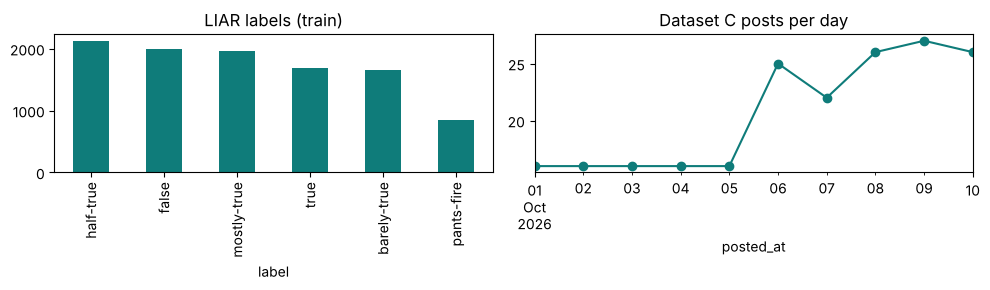

In [5]:
C["posted_at"] = pd.to_datetime(C.posted_at, utc=True); D["posted_at"] = pd.to_datetime(D.posted_at, utc=True)
print("C missing values:", C.isna().sum()[lambda s: s > 0].to_dict())
print("C posts per platform:", C.platform.value_counts().to_dict())
print("C period:", C.posted_at.min().date(), "to", C.posted_at.max().date(), "| duplicate texts:", C.text.duplicated().sum())
print("LIAR statement length (words): median", int(liar["train"].statement.str.split().str.len().median()))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
liar["train"].label.value_counts().plot(kind="bar", ax=ax[0], color="#0f7c7a", title="LIAR labels (train)")
C.set_index("posted_at").resample("1D").size().plot(ax=ax[1], marker="o", color="#0f7c7a", title="Dataset C posts per day"); plt.tight_layout(); plt.show()

## 3. NLP preprocessing

All the models below use the same preprocessing:

- lower-case the text;
- replace links with a placeholder and drop @mentions;
- shorten repeated letters;
- mark the words after a negation ("not good" becomes `not neg_good`), so the model can tell a negated word from a plain one;
- turn the text into words and word pairs, weighted by **TF-IDF** (words frequent in a text but rare overall weigh more).

In [6]:
NEGW = {"not", "no", "never", "don't", "dont", "isn't", "isnt", "wasn't", "can't", "cant", "won't", "didn't", "doesn't", "nothing", "si", "hapana", "hakuna"}
def normalise(t):
    t = str(t).lower(); t = re.sub(r"https?://\S+|www\.\S+", " http ", t); t = re.sub(r"(^|\s)@\w+", " @user ", t); return re.sub(r"(.)\1{3,}", r"\1\1\1", t)
def analyse(t):
    out, neg = [], 0
    for w in re.findall(r"[\w'#]+|[!?]", normalise(t)):
        out.append(("neg_" + w) if neg > 0 else w); neg = 3 if w in NEGW else max(0, neg - 1)
    return out + [a + " " + b for a, b in zip(out, out[1:])]
print(analyse("This is not good at all!! https://x.co @someone"))

['this', 'is', 'not', 'neg_good', 'neg_at', 'neg_all', '!', '!', 'http', 'user', 'this is', 'is not', 'not neg_good', 'neg_good neg_at', 'neg_at neg_all', 'neg_all !', '! !', '! http', 'http user']


## 4. Sentiment model: train, test and evaluate (Social Media Analysis)

Method: TF-IDF features and **logistic regression**.

- The regularisation strength *C* is chosen on the validation split.
- The model is then tested **once** on the 12,284 test tweets, which it never saw while learning.

AIVS runs the same method inside the application; *Settings → AI models* shows its stored scores and confusion matrix.

C=0.3: validation macro-F1 0.623


C=1: validation macro-F1 0.639


C=3: validation macro-F1 0.651
TEST: accuracy 0.602, macro-F1 0.598 | always-majority baseline accuracy 0.483


,precision,recall,F1,examples
negative,0.577,0.624,0.600,3972
neutral,0.652,0.579,0.613,5937
positive,0.546,0.624,0.582,2375


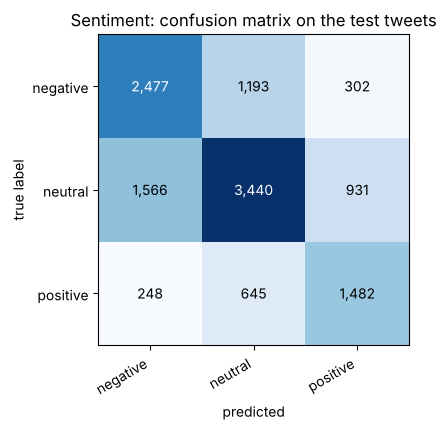

In [7]:
vs = TfidfVectorizer(analyzer=analyse, min_df=3, max_features=40000, sublinear_tf=True)
Vtr, Vva, Vte = vs.fit_transform(Xtr), vs.transform(Xva), vs.transform(Xte); best = None
for c in [0.3, 1, 3]:
    m_ = LogisticRegression(C=c, max_iter=2000, class_weight="balanced").fit(Vtr, ytr); f = precision_recall_fscore_support(yva, m_.predict(Vva), average="macro", zero_division=0)[2]
    print(f"C={c}: validation macro-F1 {f:.3f}"); best = (c, f, m_) if not best or f > best[1] else best
sent = best[2]; pte = sent.predict(Vte); p, r, f, s = precision_recall_fscore_support(yte, pte, zero_division=0)
print(f"TEST: accuracy {accuracy_score(yte, pte):.3f}, macro-F1 {f.mean():.3f} | always-majority baseline accuracy {(yte == 1).mean():.3f}")
display(pd.DataFrame({"precision": p, "recall": r, "F1": f, "examples": s}, index=SENT).round(3))
plot_cm(confusion_matrix(yte, pte), SENT, "Sentiment: confusion matrix on the test tweets")

**Optional: a pretrained transformer.** DistilBERT fine-tuned on SST-2 is downloaded from Hugging Face and used as it is; it is not trained here. It is compared with our model on 300 positive or negative test tweets. If the download is not possible, the step is skipped.

In [8]:
try:
    from transformers import pipeline
    clf_t = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
    idx = [i for i in range(len(Xte)) if yte[i] != 1][:300]
    out = clf_t([Xte[i] for i in idx], truncation=True, batch_size=32)
    print(f"DistilBERT accuracy on {len(idx)} positive/negative test tweets: {np.mean([(o['label'] == 'POSITIVE') == (yte[i] == 2) for o, i in zip(out, idx)]):.3f}")
except Exception as e:
    print("Skipped: the pretrained transformer could not be loaded here (", type(e).__name__, ").")

Skipped: the pretrained transformer could not be loaded here ( ModuleNotFoundError ).


## 5. Claim classification and analysis (Verify Information)

### 5a. Can a model tell true from false from the wording alone? (LIAR)

We train the same kind of classifier on LIAR statements, using the six PolitiFact labels and a simpler two-class version (true-leaning versus false-leaning).

This experiment shows **why AIVS does not let a model decide verdicts**: wording alone is a weak signal.

,test accuracy,macro-F1,always-majority accuracy,chance (1/classes)
six labels,0.236,0.235,0.208,0.167
two classes,0.631,0.627,0.567,0.500


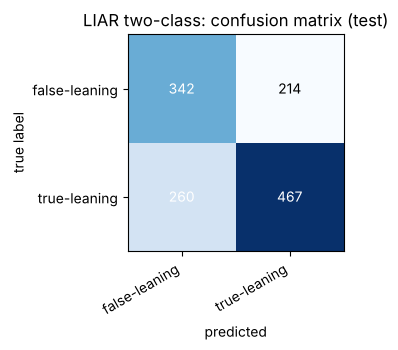

In [9]:
SIX = ["pants-fire", "false", "barely-true", "half-true", "mostly-true", "true"]; TWO = lambda l: "true-leaning" if l in ("half-true", "mostly-true", "true") else "false-leaning"
vl = TfidfVectorizer(analyzer=analyse, min_df=2, sublinear_tf=True); Ltr, Lva, Lte = (vl.fit_transform(liar["train"].statement), vl.transform(liar["valid"].statement), vl.transform(liar["test"].statement))
res = {}
for name, f_ in [("six labels", lambda l: l), ("two classes", TWO)]:
    ytr_, yva_, yte_ = [liar[s].label.map(f_).values for s in ("train", "valid", "test")]; best = None
    for c in [0.1, 0.3, 1]:
        m_ = LogisticRegression(C=c, max_iter=3000, class_weight="balanced").fit(Ltr, ytr_); acc = accuracy_score(yva_, m_.predict(Lva)); best = (c, acc, m_) if not best or acc > best[1] else best
    pr = best[2].predict(Lte); maj = pd.Series(ytr_).value_counts().idxmax()
    res[name] = {"test accuracy": round(accuracy_score(yte_, pr), 3), "macro-F1": round(precision_recall_fscore_support(yte_, pr, average="macro", zero_division=0)[2], 3), "always-majority accuracy": round((yte_ == maj).mean(), 3), "chance (1/classes)": round(1 / len(set(ytr_)), 3)}
    if name == "two classes": claim_model, two_pred, two_true = best[2], pr, yte_
display(pd.DataFrame(res).T)
plot_cm(confusion_matrix(two_true, two_pred, labels=["false-leaning", "true-leaning"]), ["false-leaning", "true-leaning"], "LIAR two-class: confusion matrix (test)")

**Reading the result.** On six labels the classifier does little better than chance. On two classes it is only modestly above always guessing. A confident-looking prediction from such a model would be wrong very often. AIVS therefore uses models to find and organise **evidence**, and the analyst's verdict must cite accepted evidence.

### 5b. Claim extraction and evidence retrieval (semantic similarity)

AIVS works in four steps:

1. It splits text into sentences and keeps the checkable ones: those with numbers, dates, named bodies, or verbs such as *said* or *confirmed*.
2. It searches earlier fact-checks for similar claims, here by TF-IDF cosine similarity over the LIAR statements.
3. It shows the matches with their published ratings as **suggested evidence** for the analyst.
4. The analyst reads them and decides.

In [10]:
CHECKABLE = re.compile(r"\d|percent|%|million|billion|said|says|confirmed|announced|according to|government|ministry|president|county|police|IEBC|WHO|will|has|have|was|were", re.I)
def extract_claims(text):
    sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) >= 5]
    return [s for s in sents if CHECKABLE.search(s) and not s.endswith("?")]
pool = pd.concat([liar["train"], liar["valid"]], ignore_index=True); vr = TfidfVectorizer(analyzer=analyse, min_df=1, sublinear_tf=True); P = vr.fit_transform(pool.statement)
def evidence(claim, k=3):
    sims = cosine_similarity(vr.transform([claim]), P).ravel(); top = sims.argsort()[::-1][:k]
    return pd.DataFrame({"similarity": sims[top].round(2), "earlier fact-checked statement": pool.statement.iloc[top].values, "published rating": pool.label.iloc[top].values, "speaker": pool.speaker.iloc[top].values})
post = "Unemployment has doubled since the president took office. Says the stimulus created no jobs at all. What do you think?"
claims = extract_claims(post); print("Checkable claims:", claims)
for c in claims: print("\nClaim:", c); display(evidence(c))

Checkable claims: ['Unemployment has doubled since the president took office.', 'Says the stimulus created no jobs at all.']

Claim: Unemployment has doubled since the president took office.


,similarity,earlier fact-checked statement,published rating,speaker
0,0.34,President Barack Obama has doubled the size of government since he took office.,pants-fire,paul-ryan
1,0.27,Says President Obama has doubled the deficit.,false,mitt-romney
2,0.26,The size of our federal government has more than doubled since the year 2000.,barely-true,scott-bruun



Claim: Says the stimulus created no jobs at all.


,similarity,earlier fact-checked statement,published rating,speaker
0,0.38,The stimulus created zero jobs.,pants-fire,national-republican-senatorial-committee
1,0.30,Six of Georgias counties have no lawyers at all.,true,hugh-thompson
2,0.15,When it comes to being effective at creating jobs (Chris Christie has not had) a record of governing for e...,half-true,martin-omalley


**Evaluating retrieval.** For a held-out LIAR statement, does the most similar earlier statement carry the same two-class rating? This measures how often the *suggested* evidence would point the right way. That is exactly why each suggestion must be read and accepted by a person.

In [11]:
q = liar["test"].sample(500, random_state=0); S = cosine_similarity(vr.transform(q.statement), P); nn = S.argmax(1)
agree = np.mean([TWO(a) == TWO(b) for a, b in zip(q.label, pool.label.iloc[nn])]); strong = S.max(1) >= 0.5
print(f"Nearest earlier statement has the same two-class rating: {agree:.3f} of 500 test statements")
print(f"Only close matches (similarity ≥ 0.5, {strong.sum()} statements): {np.mean([TWO(a) == TWO(b) for a, b, s in zip(q.label, pool.label.iloc[nn], strong) if s]) if strong.any() else float('nan'):.3f}")

Nearest earlier statement has the same two-class rating: 0.550 of 500 test statements
Only close matches (similarity ≥ 0.5, 10 statements): 0.700


## 6. Topics and similarity (Social Media Analysis, dataset C)

TF-IDF and **k-means** group similar posts. The silhouette score chooses the number of groups. Sentiment comes from the model trained in section 4, and Kiswahili posts are marked, because that model was trained on English only.

In [12]:
SW = re.compile(r"\b(?:ya|na|ni|wa|kwa|imeshuka|maji|bei|hakuna|amani|barabara|majambazi|hongera|tumechoka|tunashukuru|mbaya|ghali|mno|dawa|hospitali|inaajiri)\b", re.I)
C["language"] = np.where(C.text.str.contains(SW), "sw", "en")
C["sentiment"] = [SENT[k] for k in sent.predict(vs.transform(C.text))]; C.loc[C.language == "sw", "sentiment"] = "not classified (Kiswahili)"
STOP = set("the and for are but not you all this that with from have has was were will they their our now new".split())
tv = TfidfVectorizer(analyzer=lambda t: [w for w in analyse(t) if w not in STOP and len(w) > 2 and " " not in w]); V = tv.fit_transform(C.text)
sil = {k: silhouette_score(V, KMeans(k, n_init=10, random_state=0).fit_predict(V)) for k in range(3, 9)}; k = max(sil, key=sil.get)
km = KMeans(k, n_init=10, random_state=0).fit(V); C["topic"] = km.labels_; terms = np.array(tv.get_feature_names_out())
print("silhouette:", {a: round(b, 3) for a, b in sil.items()}, "→ k =", k)
display(pd.DataFrame([{"topic": t, "posts": int((C.topic == t).sum()), "top words": ", ".join(terms[np.argsort(-km.cluster_centers_[t])[:6]]), "example": C[C.topic == t].text.iloc[0]} for t in range(k)]).sort_values("posts", ascending=False))
display(C.sentiment.value_counts().to_frame("posts"))

silhouette: {3: 0.105, 4: 0.133, 5: 0.168, 6: 0.196, 7: 0.225, 8: 0.246} → k = 8


,topic,posts,top words,example
0,0,72,"amani, imerudi, hongera, madaktari, turkana, hospital","The clinic in Nairobi now opens on weekends, happy about this"
1,1,32,"county, boreholes, week, inspect, next, finished","Prices at the Nairobi market improved this week, good news"
6,6,32,"bei, hakuna, neg_ya, neg_hospitali, neg_dawa, bandits",Hakuna dawa hospitali ya Kakamega
3,3,16,"today, schedule, published, rationing, held, meeting",Water rationing schedule for Turkana published today
5,5,16,"thank, peace, returned, officers, point, working","Peace has returned to Kakamega, thank you to the officers"
7,7,14,"safi, sasa, maji, tunashukuru, yanapatikana, nairobi","Maji safi sasa yanapatikana Kakamega, tunashukuru"
2,2,13,"failed, explains, project, nobody, why, water",The water project in Turkana failed and nobody explains why
4,4,11,"barabara, mbovu, tumechoka, garissa, kakamega, mombasa","Barabara ya Garissa ni mbovu, tumechoka"


,posts
sentiment,
not classified (Kiswahili),70
negative,64
neutral,46
positive,26


**Repeated messages.** The same text posted by several accounts is a pattern to check, not proof of coordination. Dataset C contains one repeated claim on purpose (Garissa boreholes) and one scam message (an M-Pesa "registration fee").

In [13]:
rep = C.groupby("text").agg(posts=("account", "size"), accounts=("account", "nunique"), first=("posted_at", "min"), last=("posted_at", "max")).query("accounts >= 3").sort_values("posts", ascending=False)
rep["minutes"] = ((rep["last"] - rep["first"]).dt.total_seconds() / 60).round(0); rep[["posts", "accounts", "minutes"]].head(5)

,posts,accounts,minutes
text,,,
The county government has closed all boreholes in Garissa until further notice.,9,9,240.0
TANGAZO: Kaunti inaajiri vijana 500. Tuma Sh500 kwa M-Pesa namba 0712 000 111 ili kusajiliwa. Nafasi ni chache!,6,6,50.0
The budget debate starts on Tuesday,6,5,12413.0
"Bandits attacked a village near Nakuru, people are afraid",3,3,4526.0
"Maji safi sasa yanapatikana Garissa, tunashukuru",3,3,5047.0


## 7. A basic map (dataset C)

Only locations recorded in the data are used: the region a post is about (`region`, 40% of posts). The profile location that people type themselves (`user_location`) is shown separately, because it is less reliable.

Points are county centres with real coordinates, the same table AIVS uses (`COUNTY_XY` in `server/lib/social-analysis.js`). The map shows where posts say things happen, not where the authors are.

85 of 206 posts have a recorded region; 29 have only a self-described profile location (not mapped).


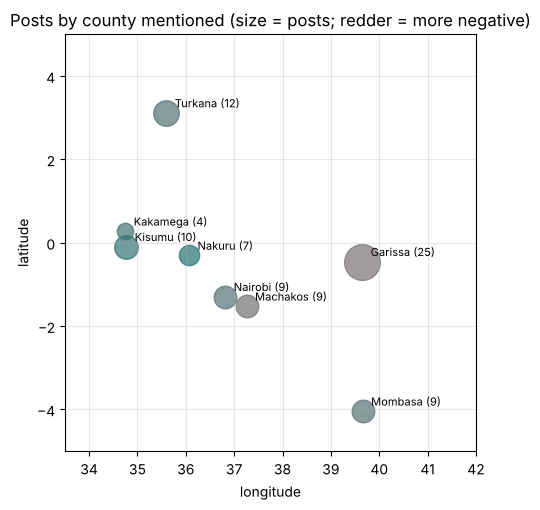

In [14]:
XY = {"Nairobi": (-1.29, 36.82), "Garissa": (-0.45, 39.65), "Kisumu": (-0.09, 34.77), "Mombasa": (-4.04, 39.66), "Nakuru": (-0.30, 36.07), "Turkana": (3.12, 35.6), "Kakamega": (0.28, 34.75), "Machakos": (-1.52, 37.26)}
reg = C.dropna(subset=["region"]).groupby("region").agg(posts=("text", "size"), negative=("sentiment", lambda s: (s == "negative").mean())).reset_index()
print(f"{C.region.notna().sum()} of {len(C)} posts have a recorded region; {C.get('user_location', pd.Series(dtype=str)).notna().sum()} have only a self-described profile location (not mapped).")
try:
    import folium
    mp = folium.Map(location=[0.3, 37.9], zoom_start=6, tiles="OpenStreetMap")
    for _, r_ in reg.iterrows():
        lat, lon = XY[r_.region]; folium.CircleMarker([lat, lon], radius=4 + r_.posts / 2, color="#0f7c7a", fill=True, fill_opacity=0.6, tooltip=f"{r_.region}: {r_.posts} posts, {r_.negative:.0%} negative").add_to(mp)
    display(mp)
except Exception as e:
    print("Interactive map not available here (", type(e).__name__, "); drawing a simple map instead.")
fig, ax = plt.subplots(figsize=(5, 5.2))
for _, r_ in reg.iterrows():
    lat, lon = XY[r_.region]; ax.scatter(lon, lat, s=40 + r_.posts * 25, c=[[r_.negative, 0.45, 0.45]], alpha=0.7); ax.annotate(f"{r_.region} ({r_.posts})", (lon, lat), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlim(33.5, 42); ax.set_ylim(-5, 5); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.grid(alpha=0.3); ax.set_title("Posts by county mentioned (size = posts; redder = more negative)")
plt.tight_layout(); plt.show()

## 8. AI Watchlist: anomaly detection (dataset D)

The watchlist uses the keywords *election, IEBC, voting, ballot*. An hour is flagged as an **unusual spike** only when all three of these hold:

- it has at least 10 matching posts;
- it has at least 3 times the average of the previous 24 hours;
- it is at least 3 standard deviations above that average.

These are the same rules and defaults as AIVS, and they avoid alerting on topics that are simply always busy. Coordination indicator: at least 3 accounts posting the same text within 10 minutes.

The full watchlist logic is in `notebooks/AIVS_AI_Watchlist_Demo.ipynb`.

577 of 1000 posts match; flagged hours:


,posts,mean,sd,spike
posted_at,,,,
2026-10-05 10:00:00+00:00,15,3.29,2.39,True
2026-10-06 14:00:00+00:00,32,2.58,2.02,True
2026-10-06 15:00:00+00:00,31,3.83,6.21,True


Coordination indicator: [(12, Timestamp('2026-10-05 10:00:00+0000', tz='UTC'), 'URGENT: IEBC officials caught changing results in Sokoni. Share before they dele')]


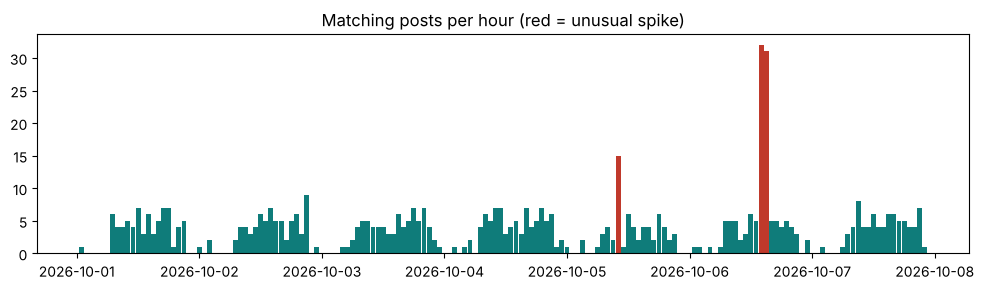

In [15]:
TERMS = ["election", "iebc", "voting", "ballot"]; mD = D[D.text.str.lower().str.contains(r"\b(?:" + "|".join(TERMS) + r")\b") & ~D.text.str.lower().str.contains("football")]
H = mD.set_index("posted_at").resample("1h").size(); base = H.shift(1).rolling(24); st = pd.DataFrame({"posts": H, "mean": base.mean(), "sd": base.std(ddof=0)})
st["spike"] = (st.posts >= 10) & (st.posts >= 3 * st["mean"]) & (st.posts >= st["mean"] + 3 * st.sd)
print(f"{len(mD)} of {len(D)} posts match; flagged hours:"); display(st[st.spike].round(2))
co = []
for txt, g in mD.sort_values("posted_at").groupby("text"):
    t = (g.posted_at - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds().values; a = g.account.values
    for j in range(len(t)):
        i = np.searchsorted(t, t[j] - 600); n = len(set(a[i:j + 1]))
        if n >= 3: co.append((n, g.posted_at.iloc[i], txt[:80]))
co = sorted(set(co), reverse=True)[:1]; print("Coordination indicator:", co)
fig, ax = plt.subplots(figsize=(10, 3)); ax.bar(st.index, st.posts, width=0.04, color=np.where(st.spike, "#c0392b", "#0f7c7a")); ax.set_title("Matching posts per hour (red = unusual spike)"); plt.tight_layout(); plt.show()

## 9. The connected workflow, and results

In the application, the three services connect like this:

1. **Social Media Analysis.** An analyst uploads dataset D (or any CSV, JSON or Excel file of public posts). Tone, topics, trends, repeated messages and the map are computed.
2. **AI Watchlist.** The active watchlist checks the import automatically and raises alerts: a keyword threshold, the unusual spike on 6 October, the emerging "ballot boxes burned" narrative, repeated messages, and the 12-account coordination indicator. Each alert has a severity and a recommended action.
3. **Verify Information.** From the spike alert, the analyst chooses "Verify a claim" and picks a post. AIVS splits it into claims and searches earlier cases, datasets and published fact-checks for evidence.
4. **The analyst decides** each claim's verdict from accepted evidence: Supported, Contradicted, Insufficient evidence or Not verifiable. A second person approves, and AIVS produces a PDF report that includes the watchlist alert as context.

### Summary of measured results (this notebook)

In [16]:
summary = pd.DataFrame([
    {"task": "Sentiment (TweetEval, 3 classes)", "test data": f"{len(yte):,} tweets", "result": f"accuracy {accuracy_score(yte, pte):.3f}, macro-F1 {precision_recall_fscore_support(yte, pte, average='macro', zero_division=0)[2]:.3f}", "baseline": f"majority {(yte == 1).mean():.3f}"},
    {"task": "Claim truth from wording (LIAR, 6 labels)", "test data": f"{len(liar['test']):,} statements", "result": f"accuracy {res['six labels']['test accuracy']}", "baseline": f"majority {res['six labels']['always-majority accuracy']}, chance {res['six labels']['chance (1/classes)']}"},
    {"task": "Claim truth from wording (LIAR, 2 classes)", "test data": f"{len(liar['test']):,} statements", "result": f"accuracy {res['two classes']['test accuracy']}", "baseline": f"majority {res['two classes']['always-majority accuracy']}"},
    {"task": "Evidence retrieval agrees in direction", "test data": "500 statements", "result": f"{agree:.3f}", "baseline": "0.5 if random"},
    {"task": "Watchlist spikes (synthetic, planted)", "test data": "1,000 posts", "result": f"{int(st.spike.sum())} flagged hours, all on the planted days", "baseline": "2 planted events"}])
summary

,task,test data,result,baseline
0,"Sentiment (TweetEval, 3 classes)","12,284 tweets","accuracy 0.602, macro-F1 0.598",majority 0.483
1,"Claim truth from wording (LIAR, 6 labels)","1,283 statements",accuracy 0.236,"majority 0.208, chance 0.167"
2,"Claim truth from wording (LIAR, 2 classes)","1,283 statements",accuracy 0.631,majority 0.567
3,Evidence retrieval agrees in direction,500 statements,0.550,0.5 if random
4,"Watchlist spikes (synthetic, planted)","1,000 posts","3 flagged hours, all on the planted days",2 planted events


## 10. Limitations

- **The models are modest.** About 59% accuracy on three-class sentiment, and close to chance for judging truth from wording alone. That second result is the reason AIVS never lets a model decide a verdict.
- **Language and context.** The training data is English, mostly US and international. Kiswahili and Kenyan context are not covered: AIVS uses a word list for Kiswahili tone and labels every result with its method.
- **Synthetic data** (datasets C and D) demonstrates the methods with known answers. It is not evidence about real public opinion.
- **Locations.** Only locations recorded in the data are mapped, and they show what posts are *about*, not who wrote them. No individual is profiled.
- **Signals, not proof.** Spikes, repeated messages and coordination indicators are signals for human review. Negative tone or criticism is not misinformation.
- **No live data here.** The live platform APIs are optional in AIVS and need keys. Nothing in this notebook collects data from platforms.